# MOVE — standalone pipeline

A self-contained, portable version of the tutorial (encode data → train a model &
explore its latent space → identify associations), plus a cell for playing with
and comparing hyperparameters.

**No YAML config files needed.** Every task is built directly from plain Python
objects, so the only things you need on a new machine (e.g. your SSH server) are:

1. `move` installed (e.g. `pip install -e .` from your fork)
2. This notebook
3. Your own raw data: one TSV/CSV file per dataset (samples as rows, features as
   columns), plus a sample-IDs file — same layout as `tutorial/data/`.

Cells marked **EDIT ME** are where you plug in your own dataset names, paths, and
hyperparameters. Everything else can be run as-is.

⚠️ **GPU note:** the current codebase does not yet move training batches to the
GPU automatically, so `use_cuda=True` will crash with a device-mismatch error
mid-training. Leave it `False` for now — ask if you'd like this fixed.

In [2]:
# Run from the tutorial folder, so relative paths (config/, data/,
# interim_data/, results/) resolve no matter where the notebook was started.
import os
from pathlib import Path

if not Path("config").is_dir() and Path("../config").is_dir():
    os.chdir("..")

## 0. Emptying previous result files

The intermediate and result files are saved in the `results` and `interim_data`
folders. Run the cell below to delete them, so the data is encoded again and
every model is retrained from scratch.

Skip this cell if you want to keep the previous files. The encoded data is
then reused (step 2 is skipped), but the models are still retrained and the
result files overwritten.

In [3]:
from pathlib import Path
import shutil

for folder in ["results", "interim_data"]:
    path = Path(folder)

    if path.exists():
        shutil.rmtree(path)
        print(f"Deleted: {path}")

Deleted: results
Deleted: interim_data


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from move.conf.models import VaeConfig
from move.conf.optim import AdamConfig
from move.conf.tasks import InputConfig, PerturbationConfig
from move.conf.training import TrainingLoopConfig
from move.tasks.associations import Associations
from move.tasks.encode_data import EncodeData
from move.tasks.latent_space_analysis import LatentSpaceAnalysis

## 1. Configure your data — EDIT ME

In [5]:
TUTORIAL_DIR = Path.cwd()

RAW_DATA_PATH = TUTORIAL_DIR / "data"
INTERIM_DATA_PATH = TUTORIAL_DIR / "interim_data"
RESULTS_PATH = TUTORIAL_DIR / "results"

# Name of the file (without extension), in RAW_DATA_PATH, listing sample IDs
# (one per line).
SAMPLE_NAMES = "random.small.ids"

# Categorical (discrete) datasets: one-hot encoded. Give each dataset a name
# (matching its filename) and, optionally, a reconstruction-loss weight
# (default 1 — raise it to make MOVE prioritize reconstructing that dataset). 
# optionall you can also assign a weight to each dataset, which will be used to weight the reconstruction loss for that dataset during training. 
# A higher weight means that the model will prioritize reconstructing that dataset more accurately, while a lower weight means that the model will 
# prioritize other datasets more. The default weight is 1.
CATEGORICAL_DATASETS = [
    {"name": "random.small.drugs", "weight": 5},
]

# Continuous datasets: choose "standardize" (z-score only) or
# "log_and_standardize" (base-2 log-transform, log2(x+1), then z-score) per
# dataset. Real proteomics/metagenomics intensities are often right-skewed
# and benefit from log2 -- but this tutorial's "random.small.*" data is
# synthetic and already near-symmetric (skew ~0), so log2 would distort it
# rather than help. Use "standardize" here; switch to "log_and_standardize"
# for real skewed data of your own.
CONTINUOUS_DATASETS = [
    {"name": "random.small.proteomics", "weight": 1, "preprocessing": "standardize"},
    {"name": "random.small.metagenomics", "weight": 1, "preprocessing": "standardize"},
]

TRAIN_FRAC = 0.9
TEST_FRAC = 0.1
VALID_FRAC = 0.0

### 1b. Explore your data (optional) — feature correlations

For each raw dataset, plots a signed Pearson-correlation heatmap (diverging
colormap, centered at 0, so anti-correlated features stand out as clearly as
correlated ones) between its features. Set `CALCULATE_MI` to also compute
mutual information — it captures non-linear dependencies too, but is much
slower for datasets with many features.

Purely exploratory: skip this cell if you already know which features you
want to include/weight.

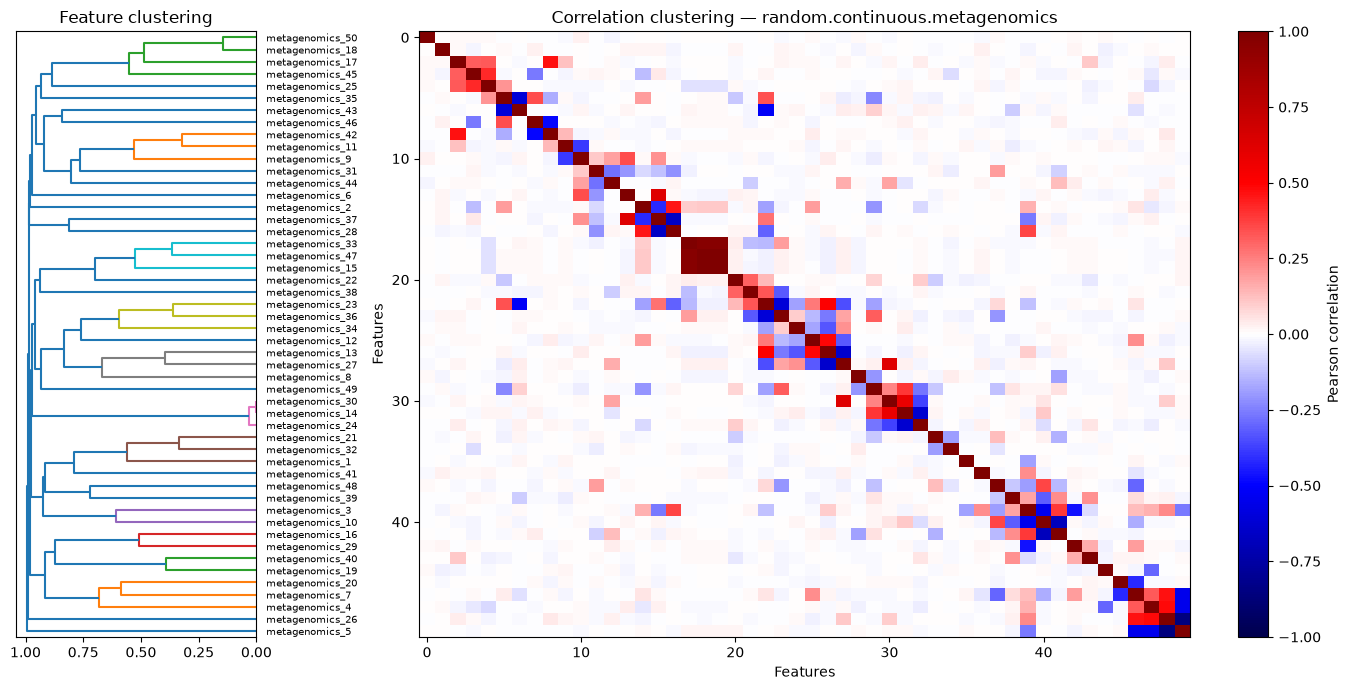

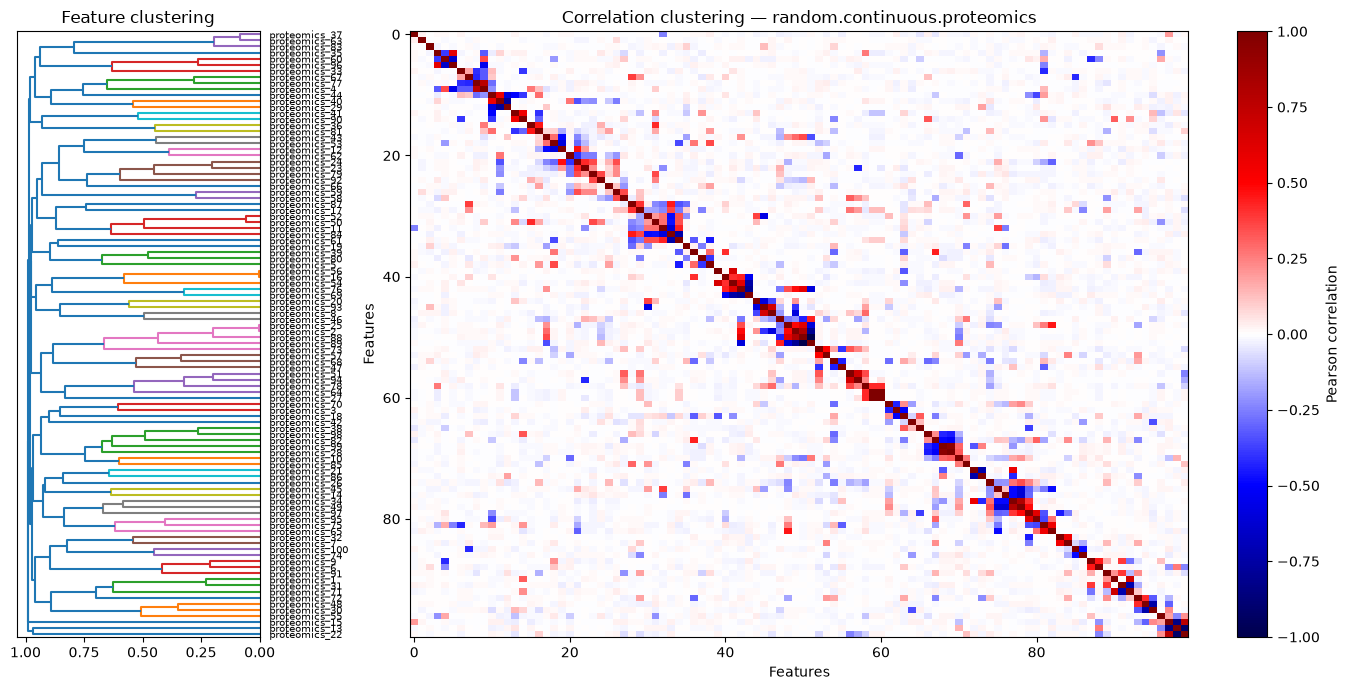

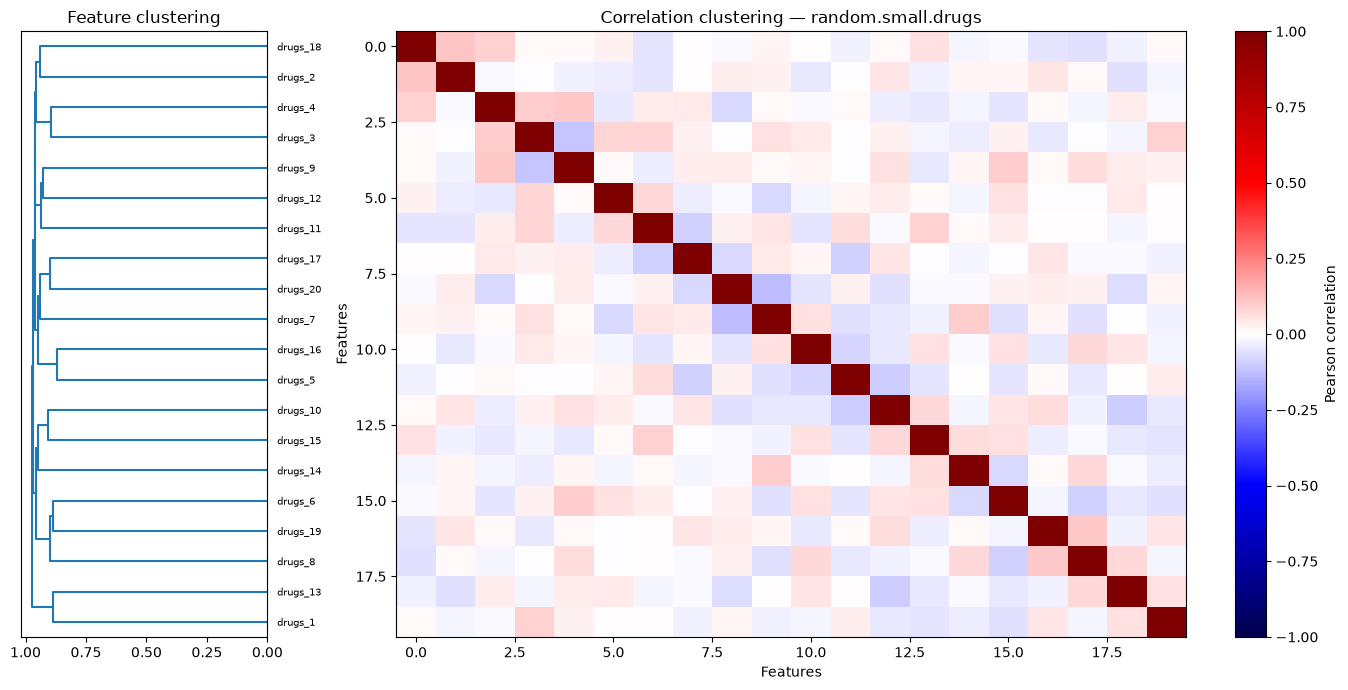

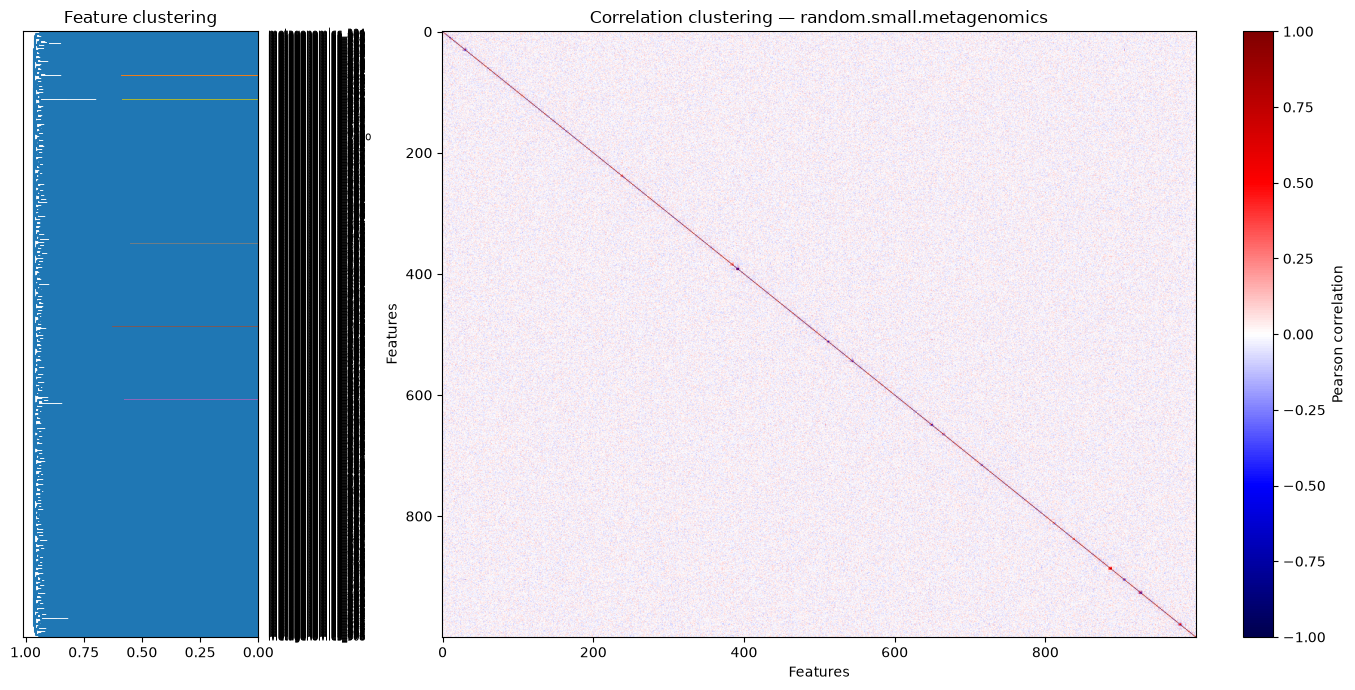

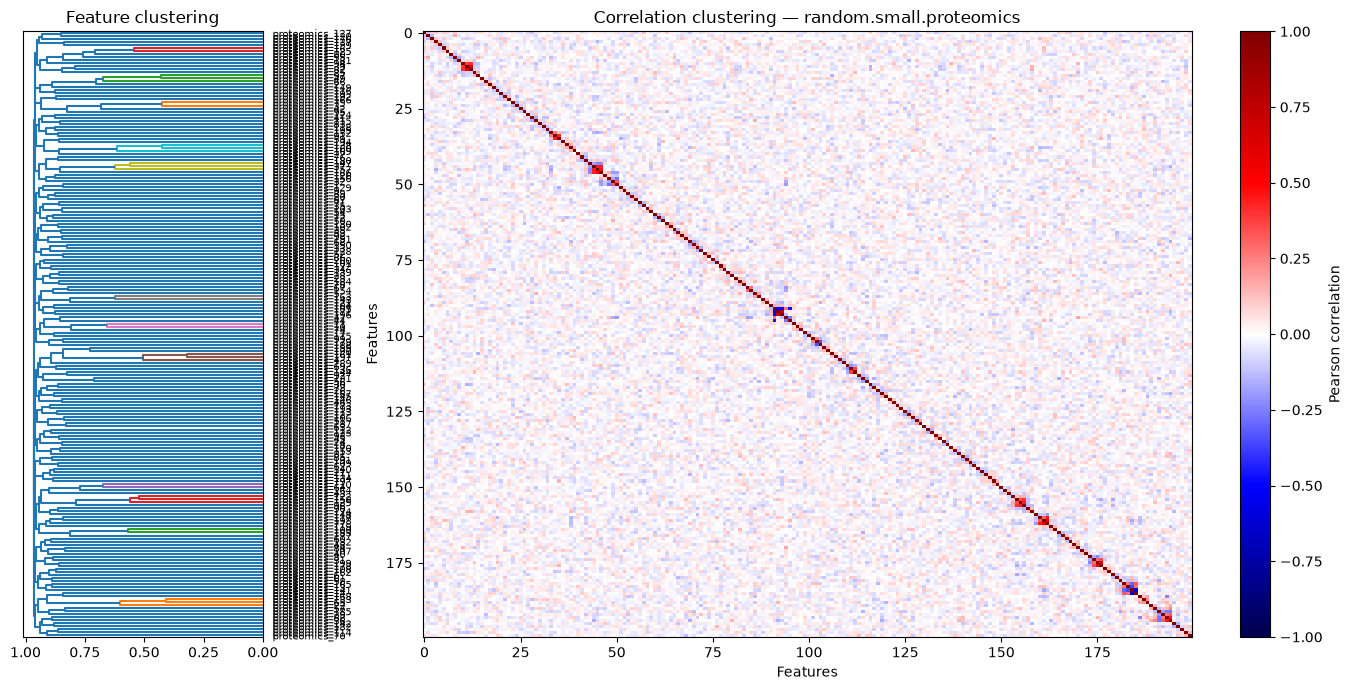

In [3]:
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
from scipy.spatial.distance import squareform


for filepath in sorted(RAW_DATA_PATH.glob("*.tsv")) + sorted(RAW_DATA_PATH.glob("*.csv")):

    sep = "\t" if filepath.suffix == ".tsv" else ","

    ds = pd.read_csv(
        filepath,
        sep=sep,
        index_col=0,
    )

    numeric_ds = ds.select_dtypes(include="number")

    if numeric_ds.shape[1] < 2:
        print(f"Skipping '{filepath.stem}': fewer than 2 numeric features")
        continue

    corr = numeric_ds.corr()

    # Remove features with no valid correlations
    valid_features = corr.columns[corr.notna().any(axis=1)]
    corr = corr.loc[valid_features, valid_features]

    if corr.shape[0] < 2:
        print(f"Skipping '{filepath.stem}': not enough valid features")
        continue

    # Use absolute correlation:
    # +0.9 and -0.9 are both considered highly similar.
    distance = 1 - np.abs(corr.to_numpy(copy=True))

    # Make sure the matrix is writable and diagonal is exactly zero
    np.fill_diagonal(distance, 0)

    # Convert square distance matrix to condensed form
    condensed_distance = squareform(
        distance,
        checks=False,
    )

    linkage_matrix = linkage(
        condensed_distance,
        method="average",
    )

    order = leaves_list(linkage_matrix)

    ordered_features = corr.index[order]
    ordered_corr = corr.loc[
        ordered_features,
        ordered_features,
    ]

    fig, axes = plt.subplots(
        ncols=2,
        figsize=(14, 7),
        gridspec_kw={"width_ratios": [1, 4]},
    )

    # Dendrogram
    dendrogram(
        linkage_matrix,
        labels=ordered_features,
        orientation="left",
        ax=axes[0],
        leaf_font_size=7,
    )

    axes[0].set_title("Feature clustering")

    # Ordered correlation matrix
    im = axes[1].imshow(
        ordered_corr,
        cmap="seismic",
        vmin=-1,
        vmax=1,
        aspect="auto",
    )

    axes[1].set_title(
        f"Correlation clustering — {filepath.stem}"
    )

    axes[1].set_xlabel("Features")
    axes[1].set_ylabel("Features")

    fig.colorbar(
        im,
        ax=axes[1],
        label="Pearson correlation",
    )

    plt.tight_layout()
    plt.show()


## 2. Encode data

Reads the raw TSV/CSV files, one-hot encodes categorical datasets, standardizes
continuous ones, and writes the result to `INTERIM_DATA_PATH`. Skipped
automatically if all datasets are already encoded there — delete the `.pt`
files in that folder to force re-encoding.

In [3]:
discrete_inputs = [
    InputConfig(d["name"], weight=d.get("weight", 1), preprocessing="one_hot_encode")
    for d in CATEGORICAL_DATASETS
]
continuous_inputs = [
    InputConfig(
        d["name"],
        weight=d.get("weight", 1),
        preprocessing=d.get("preprocessing", "standardize"),
    )
    for d in CONTINUOUS_DATASETS
]

already_encoded = bool(discrete_inputs + continuous_inputs) and all(
    (INTERIM_DATA_PATH / f"{cfg.name}.pt").exists()
    for cfg in discrete_inputs + continuous_inputs
)
if already_encoded:
    print(f"All datasets already encoded in '{INTERIM_DATA_PATH}' - skipping.")
else:
    encode_task = EncodeData(
        raw_data_path=RAW_DATA_PATH,
        interim_data_path=INTERIM_DATA_PATH,
        sample_names_filename=SAMPLE_NAMES,
        discrete_inputs=discrete_inputs,
        continuous_inputs=continuous_inputs,
        train_frac=TRAIN_FRAC,
        test_frac=TEST_FRAC,
        valid_frac=VALID_FRAC,
    )
    encode_task.run()

CATEGORICAL_NAMES = [d["name"] for d in CATEGORICAL_DATASETS]
CONTINUOUS_NAMES = [d["name"] for d in CONTINUOUS_DATASETS]
CATEGORICAL_WEIGHTS = [d.get("weight", 1) for d in CATEGORICAL_DATASETS]
CONTINUOUS_WEIGHTS = [d.get("weight", 1) for d in CONTINUOUS_DATASETS]

[INFO  - EncodeData]: Beginning task: encode data
[INFO  - EncodeData]: Encoding 'random.small.drugs'
[INFO  - EncodeData]: Encoding 'random.small.proteomics'
[INFO  - EncodeData]: Encoding 'random.small.metagenomics'


## 3. Model & training hyperparameters — EDIT ME

In [3]:
BATCH_SIZE = 30 # Batch size for training the VAE. Larger batches may improve convergence but require more GPU memory.

NUM_HIDDEN = [1000]  # sizes of the VAE's hidden encoder/decoder layers
NUM_LATENT = 150     # size of the latent space
KL_WEIGHT = 1e-4     # base weight of the KL-divergence (regularization) term
DROPOUT_RATE = 0.1 # dropout rate for the VAE's hidden layers

LEARNING_RATE = 1e-4 # learning rate for the Adam optimizer. 
MAX_EPOCHS = 40 # Number of epochs to train the VAE. 
ANNEALING_EPOCHS = MAX_EPOCHS // 2  # epochs over which the KL weight is annealed in

USE_CUDA = False  # see the GPU note at the top before flipping this on

## 4. Play & compare hyperparameters — EDIT ME

Trains one model per combo below and plots the mean reconstruction score per
dataset, on the train and test split side by side, so you can see which combo
reconstructs your data best.

Add/remove/edit combos freely; any `VaeConfig`/`TrainingLoopConfig` field can
be varied this way, not just the ones listed.

In [3]:
HP_COMBOS = {
    "baseline": dict(num_hidden=[1000], num_latent=150, kl_weight=1e-4, dropout_rate=0.1, lr=1e-4, max_epochs=40),
    "wider_hidden": dict(num_hidden=[2000], num_latent=150, kl_weight=1e-4, dropout_rate=0.1, lr=1e-4, max_epochs=40),
    "more_latent_dims": dict(num_hidden=[1000], num_latent=300, kl_weight=1e-4, dropout_rate=0.1, lr=1e-4, max_epochs=40),
    "stronger_regularization": dict(num_hidden=[1000], num_latent=150, kl_weight=1e-3, dropout_rate=0.1, lr=1e-4, max_epochs=40),
}

In [ ]:
from move.analysis.metrics import ComputeAccuracyMetrics

hp_results = []
for combo_name, hp in HP_COMBOS.items():
    print(f"--- {combo_name}: {hp}")
    combo_task = LatentSpaceAnalysis(
        interim_data_path=INTERIM_DATA_PATH,
        results_path=Path(RESULTS_PATH) / "hp_search" / combo_name,
        discrete_dataset_names=CATEGORICAL_NAMES,
        continuous_dataset_names=CONTINUOUS_NAMES,
        batch_size=BATCH_SIZE,
        model_config=VaeConfig(
            num_hidden=hp["num_hidden"],
            num_latent=hp["num_latent"],
            kl_weight=hp["kl_weight"],
            dropout_rate=hp["dropout_rate"],
            use_cuda=USE_CUDA,
            discrete_weights=CATEGORICAL_WEIGHTS,
            continuous_weights=CONTINUOUS_WEIGHTS,
        ),
        training_loop_config=TrainingLoopConfig(
            max_epochs=hp["max_epochs"],
            annealing_epochs=hp["max_epochs"] // 2,
            optimizer_config=AdamConfig(lr=hp["lr"]),
        ),
        compute_accuracy_metrics=False,
        compute_feature_importance=False,
        reducer_config=None,
        features_to_plot=None,
    )

    # Train on the train split only, so the test samples stay unseen.
    train_dataloader = combo_task.make_dataloader(split="train")
    model = combo_task.init_model(train_dataloader)
    training_loop = combo_task.init_training_loop()
    training_loop.train(model, train_dataloader)
    model.save(combo_task.output_dir / combo_task.model_filename)
    model.eval()

    # Score the reconstructions of both splits.
    for split_name in ["train", "test"]:
        dataloader = combo_task.make_dataloader(split=split_name, shuffle=False, drop_last=False)
        metrics_task = ComputeAccuracyMetrics(combo_task, model, dataloader)
        metrics_task.data_filename = f"reconstruction_metrics_{split_name}.csv"
        metrics_task.run()
        scores = pd.read_csv(combo_task.output_dir / metrics_task.data_filename)
        for dataset_name in scores.columns:
            for score in scores[dataset_name].dropna():
                hp_results.append(
                    {"combo": combo_name, "dataset": dataset_name, "split": split_name, "score": score}
                )

hp_results_df = pd.DataFrame(hp_results)
hp_results_df.groupby(["combo", "dataset", "split"])["score"].mean().unstack("split")

--- baseline: {'num_hidden': [1000], 'num_latent': 150, 'kl_weight': 0.0001, 'dropout_rate': 0.1, 'lr': 0.0001, 'max_epochs': 40}


[INFO  - LatentSpaceAnalysis]: Epoch 10
[INFO  - LatentSpaceAnalysis]: Epoch 20
[INFO  - LatentSpaceAnalysis]: Epoch 30
[INFO  - LatentSpaceAnalysis]: Epoch 40
[INFO  - LatentSpaceAnalysis]: Computing accuracy metrics
[INFO  - LatentSpaceAnalysis]: Computing accuracy metrics


--- wider_hidden: {'num_hidden': [2000], 'num_latent': 150, 'kl_weight': 0.0001, 'dropout_rate': 0.1, 'lr': 0.0001, 'max_epochs': 40}


[INFO  - LatentSpaceAnalysis]: Epoch 10
[INFO  - LatentSpaceAnalysis]: Epoch 20
[INFO  - LatentSpaceAnalysis]: Epoch 30
[INFO  - LatentSpaceAnalysis]: Epoch 40
[INFO  - LatentSpaceAnalysis]: Computing accuracy metrics
[INFO  - LatentSpaceAnalysis]: Computing accuracy metrics


--- more_latent_dims: {'num_hidden': [1000], 'num_latent': 300, 'kl_weight': 0.0001, 'dropout_rate': 0.1, 'lr': 0.0001, 'max_epochs': 40}


[INFO  - LatentSpaceAnalysis]: Epoch 10
[INFO  - LatentSpaceAnalysis]: Epoch 20
[INFO  - LatentSpaceAnalysis]: Epoch 30
[INFO  - LatentSpaceAnalysis]: Epoch 40
[INFO  - LatentSpaceAnalysis]: Computing accuracy metrics
[INFO  - LatentSpaceAnalysis]: Computing accuracy metrics


--- stronger_regularization: {'num_hidden': [1000], 'num_latent': 150, 'kl_weight': 0.001, 'dropout_rate': 0.1, 'lr': 0.0001, 'max_epochs': 40}


[INFO  - LatentSpaceAnalysis]: Epoch 10
[INFO  - LatentSpaceAnalysis]: Epoch 20
[INFO  - LatentSpaceAnalysis]: Epoch 30
[INFO  - LatentSpaceAnalysis]: Epoch 40
[INFO  - LatentSpaceAnalysis]: Computing accuracy metrics
[INFO  - LatentSpaceAnalysis]: Computing accuracy metrics


split                                                  test     train
combo                   dataset                                      
baseline                random.small.drugs         0.871609  0.998592
                        random.small.metagenomics  0.078229  0.338962
                        random.small.proteomics    0.158426  0.462161
more_latent_dims        random.small.drugs         0.900517  0.999283
                        random.small.metagenomics  0.079432  0.345536
                        random.small.proteomics    0.177222  0.480316
stronger_regularization random.small.drugs         0.880636  0.997434
                        random.small.metagenomics  0.076434  0.332626
                        random.small.proteomics    0.167610  0.452259
wider_hidden            random.small.drugs         0.906770  0.999766
                        random.small.metagenomics  0.105552  0.520514
                        random.small.proteomics    0.174940  0.630680

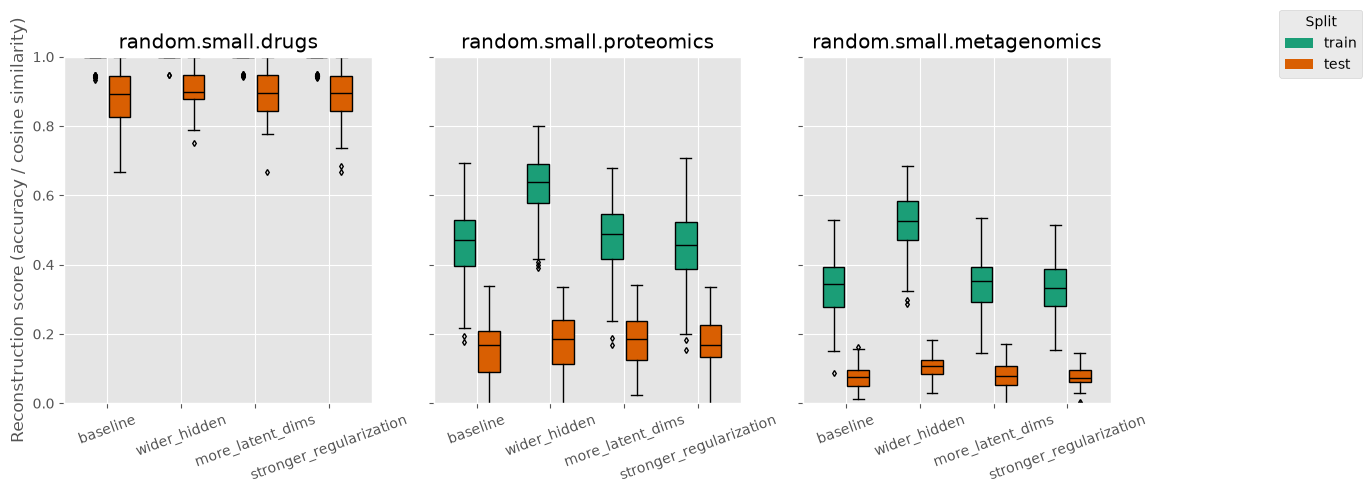

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from move.visualization import show_figure
from move.visualization.style import (
    DEFAULT_PLOT_STYLE,
    DEFAULT_QUALITATIVE_PALETTE,
    color_cycle,
    style_settings,
)

combos = list(HP_COMBOS.keys())
datasets = hp_results_df["dataset"].unique()
splits = ["train", "test"]
x = np.arange(len(combos)) * 1.2  # one slot per combo, extra gap between slots

with style_settings(DEFAULT_PLOT_STYLE), color_cycle(DEFAULT_QUALITATIVE_PALETTE):
    colors = [c["color"] for c in list(plt.rcParams["axes.prop_cycle"])[: len(splits)]]
    fig, axs = plt.subplots(ncols=len(datasets), sharey=True, figsize=(4.5 * len(datasets), 4.5), squeeze=False)
    for ax, dataset_name in zip(axs[0], datasets):
        for split_name, color, offset in zip(splits, colors, (0.0, 0.4)):
            data = [
                hp_results_df.loc[
                    (hp_results_df["combo"] == combo)
                    & (hp_results_df["dataset"] == dataset_name)
                    & (hp_results_df["split"] == split_name),
                    "score",
                ]
                for combo in combos
            ]
            ax.boxplot(
                data,
                positions=x + offset,
                widths=0.35,
                patch_artist=True,
                boxprops=dict(facecolor=color),
                medianprops=dict(color="black"),
                flierprops=dict(marker="d", markersize=3),
            )
        ax.set(xticks=x + 0.2, xticklabels=combos, ylim=(0, 1), title=dataset_name)
        ax.tick_params(axis="x", rotation=20)
    axs[0, 0].set_ylabel("Reconstruction score (accuracy / cosine similarity)")
    fig.legend(
        handles=[plt.Rectangle((0, 0), 1, 1, facecolor=c) for c in colors],
        labels=splits,
        title="Split",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
show_figure(fig)

## 5. Train a model & explore its latent space

Same task the tutorial's "04 Latent space analysis" notebook uses. Trains a VAE
(overwriting any model saved at `RESULTS_PATH/latent_space/model.pt`), then
projects the data into its latent space, scores reconstruction accuracy, and
computes feature importance. Plots (loss curve, reconstruction metrics, latent
space) are saved to `RESULTS_PATH/latent_space/` and shown inline below.

[INFO  - LatentSpaceAnalysis]: Epoch 10
[INFO  - LatentSpaceAnalysis]: Epoch 20
[INFO  - LatentSpaceAnalysis]: Epoch 30
[INFO  - LatentSpaceAnalysis]: Epoch 40


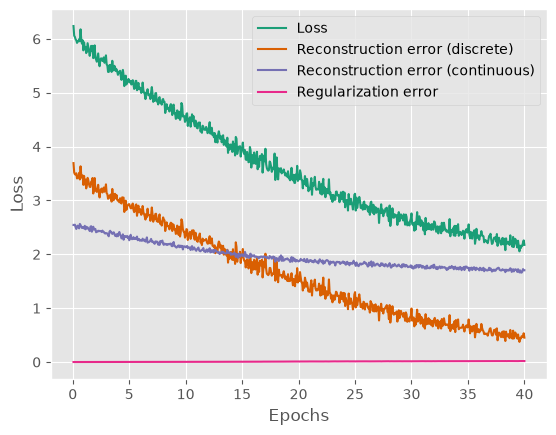

[INFO  - LatentSpaceAnalysis]: Compressing input data
[INFO  - LatentSpaceAnalysis]: Computing accuracy metrics


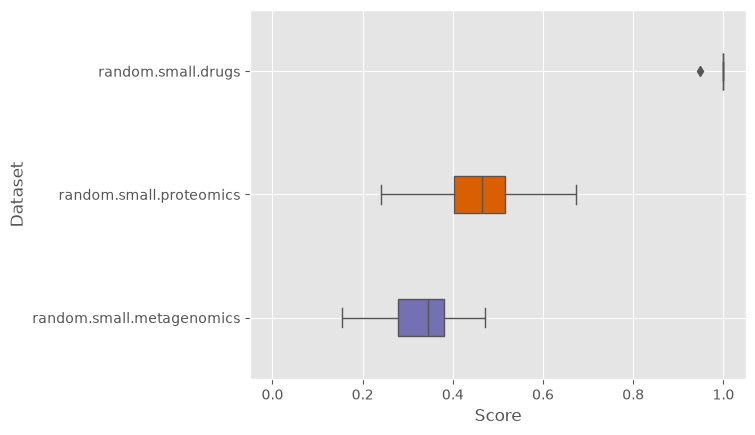

[INFO  - LatentSpaceAnalysis]: Computing feature importance: 'random.small.drugs'
[INFO  - LatentSpaceAnalysis]: Computing feature importance: 'random.small.proteomics'
[INFO  - LatentSpaceAnalysis]: Computing feature importance: 'random.small.metagenomics'


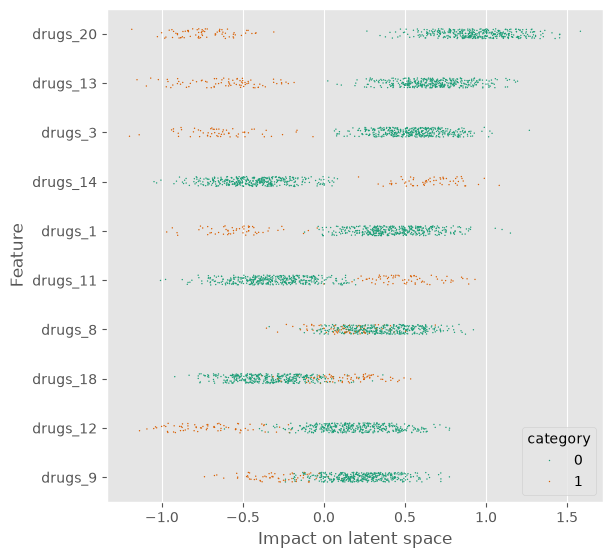

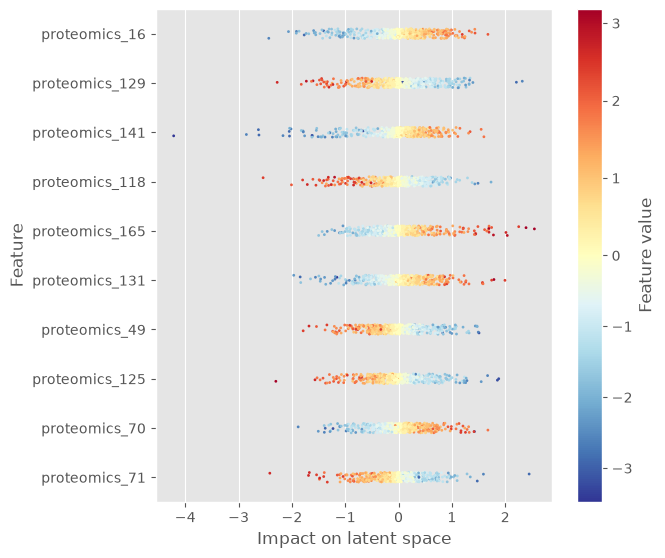

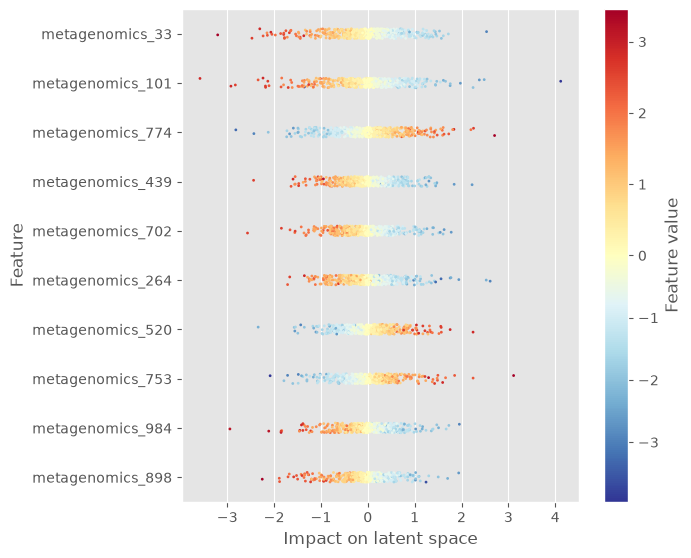

In [4]:
REDUCER_CONFIG = None
FEATURES_TO_PLOT = None  # e.g. ["my_drug_dataset_20"] to color latent space plots by a feature

model_config = VaeConfig(
    num_hidden=NUM_HIDDEN,
    num_latent=NUM_LATENT,
    kl_weight=KL_WEIGHT,
    dropout_rate=DROPOUT_RATE,
    use_cuda=USE_CUDA,
    discrete_weights=CATEGORICAL_WEIGHTS,
    continuous_weights=CONTINUOUS_WEIGHTS,
)
training_loop_config = TrainingLoopConfig(
    max_epochs=MAX_EPOCHS,
    annealing_epochs=ANNEALING_EPOCHS,
    optimizer_config=AdamConfig(lr=LEARNING_RATE),
)

latent_task = LatentSpaceAnalysis(
    interim_data_path=INTERIM_DATA_PATH,
    results_path=RESULTS_PATH,
    discrete_dataset_names=CATEGORICAL_NAMES,
    continuous_dataset_names=CONTINUOUS_NAMES,
    batch_size=BATCH_SIZE,
    model_config=model_config,
    training_loop_config=training_loop_config,
    compute_accuracy_metrics=True,
    compute_feature_importance=True,
    reducer_config=REDUCER_CONFIG,
    features_to_plot=FEATURES_TO_PLOT,
)
latent_task.run()

### 5b. Explore the latent space — EDIT ME

Re-plots the 2D latent space using the model just trained above, without
retraining anything. Change `COLOR_BY_FEATURE` to color the scatterplot by
any feature from your datasets, and `REDUCER_CONFIG` to switch between PCA
and t-SNE for the dimensionality reduction. Re-run this cell as many times
as you like to try different features/reducers.

[INFO  - LatentSpaceAnalysis]: File 'latent_space.csv' already exists. It will be overwritten.
[INFO  - LatentSpaceAnalysis]: Compressing input data
[INFO  - LatentSpaceAnalysis]: Reducing data to two dimensions


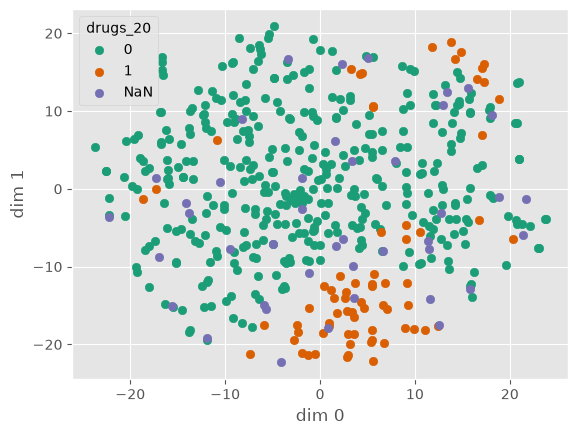

In [43]:
from move.conf.tasks import PcaConfig, TsneConfig
from move.models.base import reload_vae
from move.tasks.latent_space_analysis import Project

COLOR_BY_FEATURE = "drugs_20"  # a feature name from any of your datasets
REDUCER_CONFIG = TsneConfig()  # or PcaConfig(), to change the dimensionality reduction

model = reload_vae(latent_task.output_dir / latent_task.model_filename)
model.eval()
all_dataloader = latent_task.make_dataloader(shuffle=False, drop_last=False)

project_subtask = Project(model, all_dataloader, REDUCER_CONFIG, output_dir=latent_task.output_dir)
project_subtask.parent = latent_task
project_subtask.run()
project_subtask.plot([COLOR_BY_FEATURE])

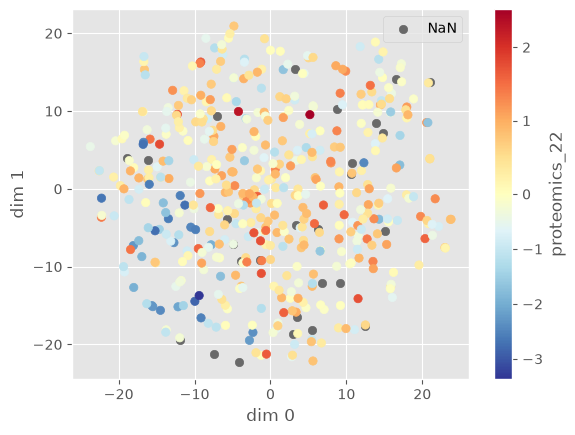

In [4]:
COLOR_BY_FEATURE = "proteomics_22" 
project_subtask.plot([COLOR_BY_FEATURE])

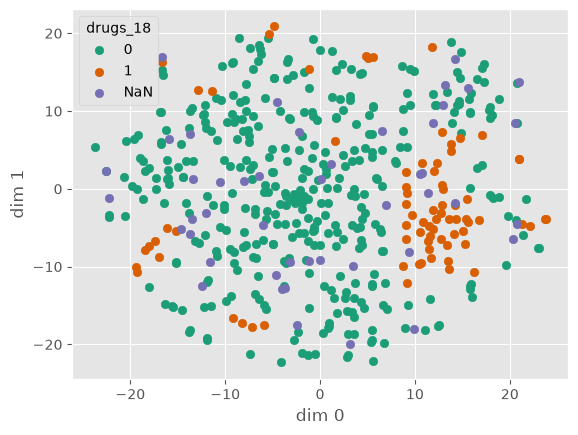

In [4]:
COLOR_BY_FEATURE = "drugs_18" 
project_subtask.plot([COLOR_BY_FEATURE])

--- random.small.drugs ---
drugs_20    0.830817
drugs_13    0.602804
drugs_3     0.517179
dtype: float64
--- random.small.metagenomics ---
metagenomics_33     0.559599
metagenomics_101    0.555810
metagenomics_774    0.534251
dtype: float64
--- random.small.proteomics ---
proteomics_16     0.451217
proteomics_129    0.446404
proteomics_141    0.416199
dtype: float64


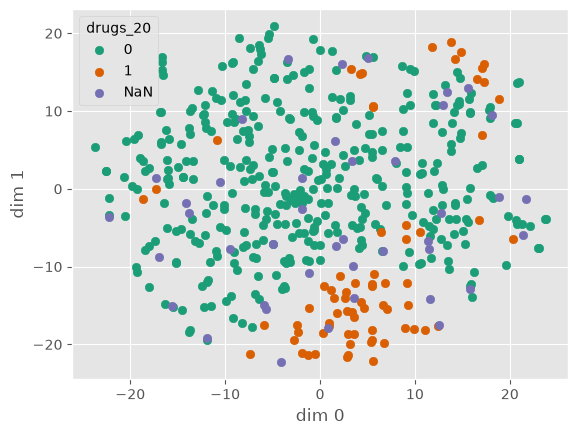

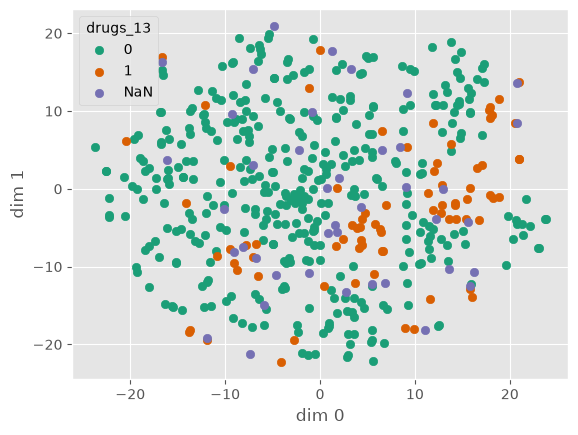

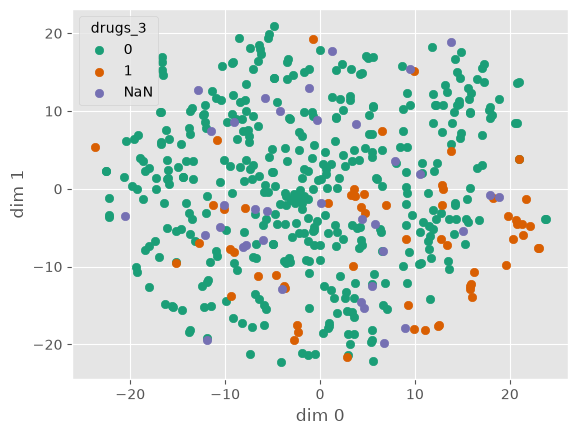

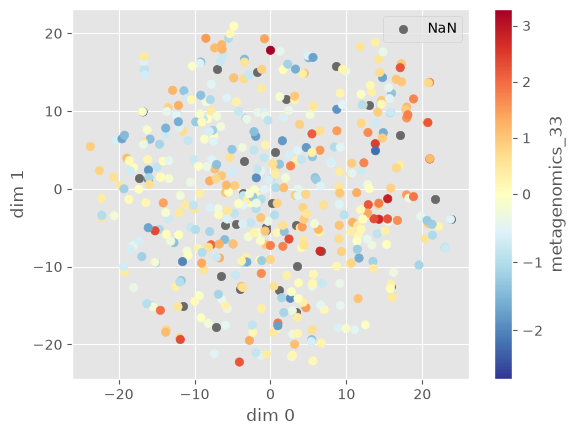

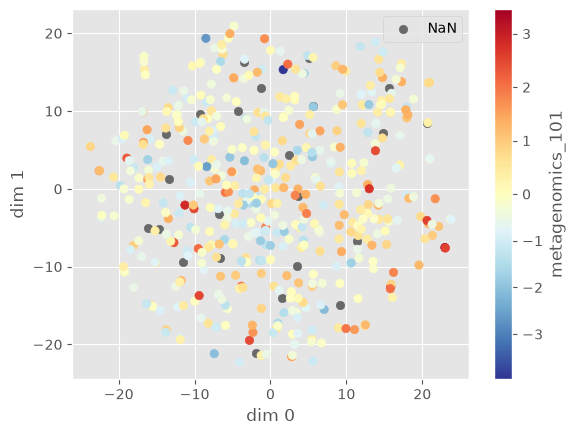

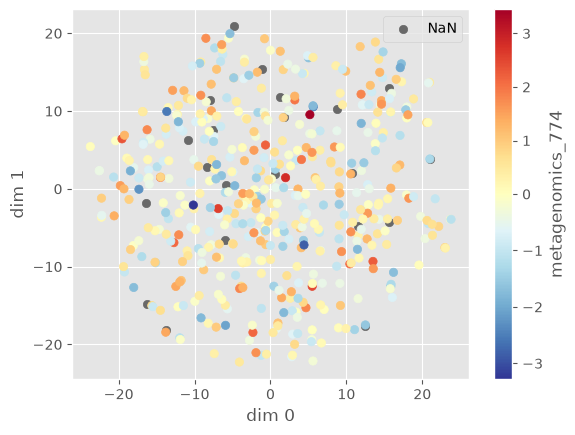

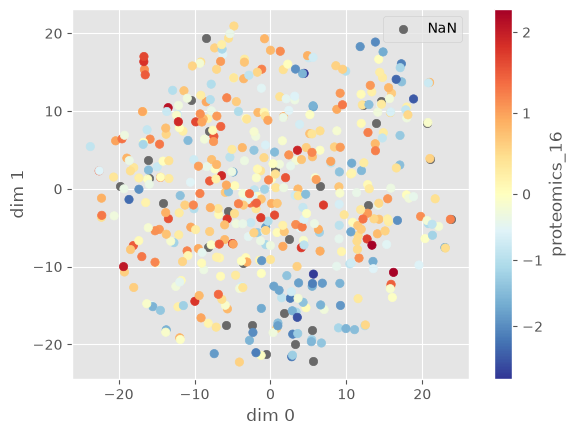

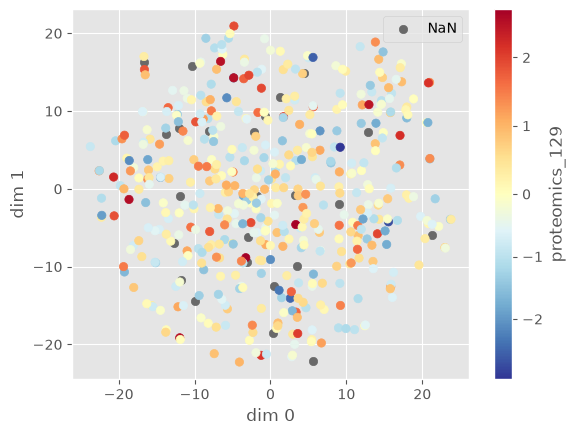

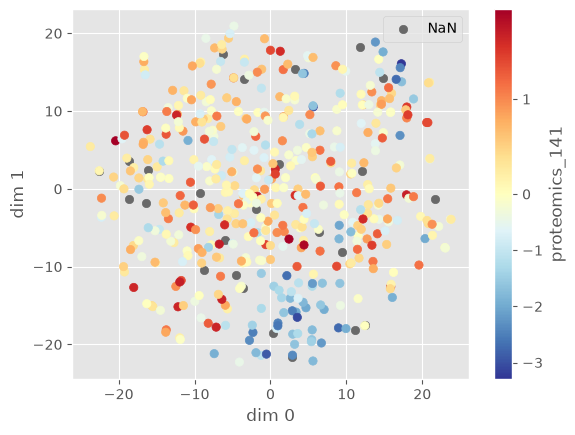

In [46]:
N_TOP_FEATURES = 3  # how many top-impact features to plot, per dataset

# One feature_importance_<dataset>.csv per dataset (discrete + continuous);
# each column is a feature, each row a sample's effect on the latent space.
fi_paths = sorted(latent_task.output_dir.glob("feature_importance_*.csv"))

top_features = []
for path in fi_paths:
    dataset_name = path.stem.removeprefix("feature_importance_")
    # Mean absolute impact per feature, within this dataset only.
    importance = pd.read_csv(path).abs().mean()
    top = importance.sort_values(ascending=False).head(N_TOP_FEATURES)
    print(f"--- {dataset_name} ---")
    print(top)
    top_features.extend(top.index.tolist())

project_subtask.plot(top_features)

## 6. Identify associations — EDIT ME

Perturbs a feature (or a whole dataset) and checks which continuous features
are significantly associated with it, via the Bayesian method.

⚠️ Note: the alternative t-test method mentioned in the original MOVE paper has
not been reimplemented for this codebase's current version — this always uses
the Bayesian approach.

By default this reuses `model_config`/`training_loop_config` from step 5; edit
them here first if you want different hyperparameters for this step.

In [47]:
TARGET_DATASET = "random.small.drugs"  # a name from CATEGORICAL_DATASETS above
TARGET_FEATURE = None                # perturb one feature only, or None for all features in TARGET_DATASET
TARGET_VALUE = 1                     # value to set the perturbed feature(s) to

NUM_REFITS = 40       # number of models to train and average results over
SIG_THRESHOLD = 0.05  # FDR threshold below which an association is "significant"

assoc_task = Associations(
    interim_data_path=INTERIM_DATA_PATH,
    results_path=RESULTS_PATH,
    discrete_dataset_names=CATEGORICAL_NAMES,
    continuous_dataset_names=CONTINUOUS_NAMES,
    batch_size=BATCH_SIZE,
    model_config=model_config,
    training_loop_config=training_loop_config,
    perturbation_config=PerturbationConfig(
        target_dataset_name=TARGET_DATASET,
        target_feature_name=TARGET_FEATURE,
        target_value=TARGET_VALUE,
    ),
    num_refits=NUM_REFITS,
    sig_threshold=SIG_THRESHOLD,
    write_only_sig=False,  # keep all features so the volcano plot below has a background
)
assoc_task.run()

associations = pd.read_csv(assoc_task.output_dir / "associations.csv")
associations.sort_values("fdr").head(20)

[INFO  - Associations]: Perturbing (1/20)
[INFO  - Associations]: Perturbing (2/20)
[INFO  - Associations]: Perturbing (3/20)
[INFO  - Associations]: Perturbing (4/20)
[INFO  - Associations]: Perturbing (5/20)
[INFO  - Associations]: Perturbing (6/20)
[INFO  - Associations]: Perturbing (7/20)
[INFO  - Associations]: Perturbing (8/20)
[INFO  - Associations]: Perturbing (9/20)
[INFO  - Associations]: Perturbing (10/20)
[INFO  - Associations]: Perturbing (11/20)
[INFO  - Associations]: Perturbing (12/20)
[INFO  - Associations]: Perturbing (13/20)
[INFO  - Associations]: Perturbing (14/20)
[INFO  - Associations]: Perturbing (15/20)
[INFO  - Associations]: Perturbing (16/20)
[INFO  - Associations]: Perturbing (17/20)
[INFO  - Associations]: Perturbing (18/20)
[INFO  - Associations]: Perturbing (19/20)
[INFO  - Associations]: Perturbing (20/20)
[INFO  - Associations]: Complete! Writing out results
[INFO  - Associations]: Significant associations found: 79


,perturbed_feature,target_feature,prob,bayes_k,fdr,pred_significant
0,drugs_15,proteomics_192,1.000000,-18.420681,0.000000,True
1,drugs_16,proteomics_177,1.000000,18.420681,0.000000,True
2,drugs_1,metagenomics_898,1.000000,18.420681,0.000000,True
3,drugs_6,proteomics_31,1.000000,18.420681,0.000000,True
4,drugs_9,metagenomics_835,1.000000,-18.420681,0.000000,True
5,drugs_2,proteomics_127,0.975000,3.663562,0.004167,True
6,drugs_11,metagenomics_414,0.975000,3.663562,0.007143,True
7,drugs_3,proteomics_90,0.975000,3.663562,0.009375,True
8,drugs_2,metagenomics_930,0.975000,-3.663561,0.011111,True
9,drugs_3,metagenomics_80,0.975000,-3.663561,0.012500,True


### 6b. Visualize associations — volcano plot

The Bayesian association test produces, per candidate feature: `bayes_k` (the
signed log-odds that the perturbation increases vs. decreases it — the
"effect") and `fdr` (confidence). Plotting one against the other, as a volcano
plot, is the standard way to see both at a glance: points far from `x=0` and
above the dashed line are your strongest, most confident hits.

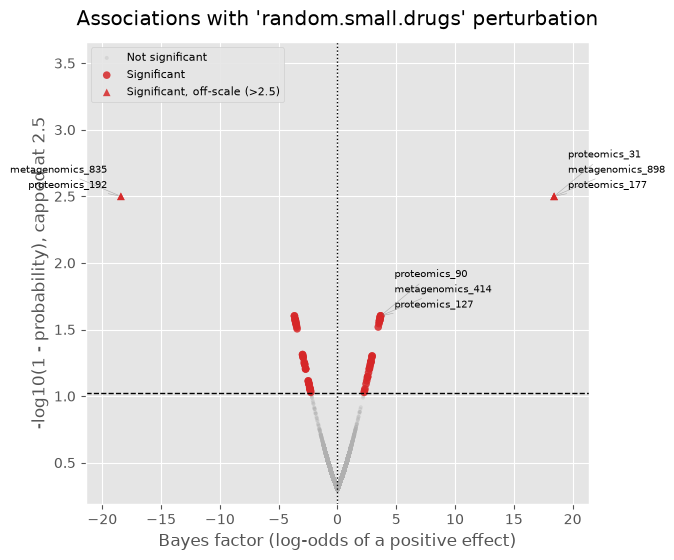

In [48]:
from scipy.special import expit

from move.visualization import show_figure
from move.visualization.style import DEFAULT_PLOT_STYLE, style_settings

TOP_N_LABELS = 8   # how many of the most significant hits to label by name
Y_CAP = 2.5         # display cap for -log10(1 - probability); 

plot_df = associations.copy()

plot_df["neg_log10_1mp"] = -np.log10(expit(-plot_df["bayes_k"].abs().astype(np.float64)))

plot_df["capped"] = plot_df["neg_log10_1mp"] > Y_CAP
plot_df["y_plot"] = plot_df["neg_log10_1mp"].clip(upper=Y_CAP)

with style_settings(DEFAULT_PLOT_STYLE):
    fig, ax = plt.subplots(figsize=(6.5, 6))

    background = plot_df[~plot_df["pred_significant"]]
    ax.scatter(
        background["bayes_k"], background["y_plot"],
        c="#b0b0b0", s=8, alpha=0.3, edgecolors="none",
        label="Not significant", rasterized=True,
    )

    sig = plot_df[plot_df["pred_significant"]]
    for capped, marker, label in [
        (False, "o", "Significant"),
        (True, "^", f"Significant, off-scale (>{Y_CAP:g})"),
    ]:
        subset = sig[sig["capped"] == capped]
        if len(subset):
            ax.scatter(
                subset["bayes_k"], subset["y_plot"],
                c="#d62728", marker=marker, s=30, alpha=0.85,
                edgecolors="none", label=label,
            )

    if len(sig) and len(background):
        cutoff = (background["neg_log10_1mp"].max() + sig["neg_log10_1mp"].min()) / 2
        ax.axhline(cutoff, color="black", linestyle="--", linewidth=1)
    ax.axvline(0, color="black", linestyle=":", linewidth=1)

    top_hits = plot_df.nsmallest(TOP_N_LABELS, "fdr")
    stack_counts: dict[tuple[float, float], int] = {}
    max_stack = 0
    for _, row in top_hits.iterrows():
        key = (round(row["bayes_k"], 2), round(row["y_plot"], 2))
        stack_idx = stack_counts.get(key, 0)
        stack_counts[key] = stack_idx + 1
        max_stack = max(max_stack, stack_idx)
        side = 1 if row["bayes_k"] >= 0 else -1
        ax.annotate(
            row["target_feature"], (row["bayes_k"], row["y_plot"]),
            fontsize=7, ha="left" if side > 0 else "right",
            xytext=(side * 10, 6 + 11 * stack_idx), textcoords="offset points",
            arrowprops=dict(arrowstyle="-", lw=0.4, color="gray", alpha=0.6),
        )

    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + 0.35 * (max_stack + 1))
    ax.set_xlim(plot_df["bayes_k"].min() - 3, plot_df["bayes_k"].max() + 3)

    ax.set(
        xlabel="Bayes factor (log-odds of a positive effect)",
        ylabel=f"-log10(1 - probability), capped at {Y_CAP:g}",
    )
    ax.set_title(f"Associations with '{TARGET_DATASET}' perturbation", pad=12)
    ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
show_figure(fig)

### 6c. Test: continuous feature perturbations

Until now, perturbing a feature meant replacing every sample's value with one
fixed `target_value` — sensible for a categorical drug feature ("set to 1"),
less so for a continuous omics feature, since a single hardcoded number
rarely means the same thing across differently-scaled features.

`PerturbationConfig` now takes an optional `perturbation_type`, continuous
datasets only:

- `"value"` (default, unchanged) — replace with `target_value`
- `"minimum"` / `"maximum"` — replace with the feature's own dataset-wide min/max
- `"plus_std"` / `"minus_std"` — add/subtract one standard deviation **to each
  sample's own existing value**, rather than replacing it (this one needed a
  real code change: the existing `Perturbation` only knew how to broadcast a
  fixed replacement value, not offset each sample individually)

Below, we perturb a single continuous feature with each type and compare how
many associations each finds — a quick way to confirm the new code path
actually runs through the full `Associations` task, not just in isolation.

In [49]:
CONTINUOUS_TARGET_DATASET = "random.small.proteomics" 
CONTINUOUS_TARGET_FEATURE = None  # None = every feature in CONTINUOUS_TARGET_DATASET (200 for proteomics)

PERTURBATION_TYPES = ["plus_std"] # Select one of these ["minimum", "maximum", "plus_std", "minus_std"] 
CONTINUOUS_NUM_REFITS = 3  # lower than NUM_REFITS above -- see runtime note below

continuous_perturbation_results = {}
for ptype in PERTURBATION_TYPES:
    print(f"--- perturbation_type={ptype} ---")
    task = Associations(
        interim_data_path=INTERIM_DATA_PATH,
        results_path=Path(RESULTS_PATH) / "continuous_perturbation_test" / ptype,
        discrete_dataset_names=CATEGORICAL_NAMES,
        continuous_dataset_names=CONTINUOUS_NAMES,
        batch_size=BATCH_SIZE,
        model_config=model_config,
        training_loop_config=training_loop_config,
        perturbation_config=PerturbationConfig(
            target_dataset_name=CONTINUOUS_TARGET_DATASET,
            target_feature_name=CONTINUOUS_TARGET_FEATURE,
            target_value=0.0,  # ignored for every type here except "value"
            perturbation_type=ptype,
        ),
        num_refits=CONTINUOUS_NUM_REFITS,
        sig_threshold=SIG_THRESHOLD,
        write_only_sig=False,
    )
    task.run()
    continuous_perturbation_results[ptype] = pd.read_csv(task.output_dir / "associations.csv")

# Which specific (perturbed_feature, target_feature) pairs were significant under
# each perturbation type -- not just how many.
significant_by_type = []
for ptype, df in continuous_perturbation_results.items():
    sig = df[df["pred_significant"]].copy()
    sig.insert(0, "perturbation_type", ptype)
    significant_by_type.append(sig)

significant_associations = pd.concat(significant_by_type, ignore_index=True)
significant_associations.sort_values(["perturbation_type", "fdr"])

--- perturbation_type=plus_std ---


[INFO  - Associations]: Perturbing (1/200)
[INFO  - Associations]: Perturbing (2/200)
[INFO  - Associations]: Perturbing (3/200)
[INFO  - Associations]: Perturbing (4/200)
[INFO  - Associations]: Perturbing (5/200)
[INFO  - Associations]: Perturbing (6/200)
[INFO  - Associations]: Perturbing (7/200)
[INFO  - Associations]: Perturbing (8/200)
[INFO  - Associations]: Perturbing (9/200)
[INFO  - Associations]: Perturbing (10/200)
[INFO  - Associations]: Perturbing (11/200)
[INFO  - Associations]: Perturbing (12/200)
[INFO  - Associations]: Perturbing (13/200)
[INFO  - Associations]: Perturbing (14/200)
[INFO  - Associations]: Perturbing (15/200)
[INFO  - Associations]: Perturbing (16/200)
[INFO  - Associations]: Perturbing (17/200)
[INFO  - Associations]: Perturbing (18/200)
[INFO  - Associations]: Perturbing (19/200)
[INFO  - Associations]: Perturbing (20/200)
[INFO  - Associations]: Perturbing (21/200)
[INFO  - Associations]: Perturbing (22/200)
[INFO  - Associations]: Perturbing (23/20

,perturbation_type,perturbed_feature,target_feature,prob,bayes_k,fdr,pred_significant
